# Module 3: Distance-method pairs trading (Gatev, Goetzmann & Rouwenhorst 2006)

The canonical academic pairs strategy, and the benchmark every later method is compared
against. It needs no econometrics: rescale prices to start at 1, pair up the stocks whose
rescaled prices stayed closest, and bet that a pair which drifts apart will come back
together.

1. Simulate first: one genuine pair, one impostor, one unrelated stock
2. The threshold rule
3. Real data: select pairs in one formation period
4. One trading period, step by step
5. Roll it through 2005–2025
6. How trades end: convergence vs divergence
7. Trade at the signal close, or wait one day?
8. Exercises

Lecture notes: [`lecture.md`](lecture.md). New code: `statarb.pairs.distance`,
`statarb.signals`.

In [1]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from statarb import data, universe
from statarb.config import TRADING_DAYS
from statarb.pairs import distance
from statarb.signals import threshold_positions

logging.getLogger("yfinance").setLevel(logging.CRITICAL)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

FORMATION, TRADING, N_PAIRS, ENTRY = 252, 126, 20, 2.0  # GGR: 12 months, 6 months, top 20, 2σ

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


def performance(daily: pd.Series) -> pd.Series:
    """Annualised mean, volatility and their ratio (a Sharpe ratio without the risk-free rate)."""
    mean, vol = daily.mean() * TRADING_DAYS, daily.std() * np.sqrt(TRADING_DAYS)
    return pd.Series({"ann. return": mean, "ann. volatility": vol, "Sharpe": mean / vol})

## 1. Simulate first

Three years of four synthetic stocks:

- **A** and **B** share a random-walk trend and differ by a mean-reverting (AR(1)) log
  spread: a genuine pair;
- **D** follows the same trend plus slow independent drift: close to A, but its gap to A
  never comes back;
- **C** is an unrelated random walk.

In [2]:
rng = np.random.default_rng(4)
n = 3 * TRADING_DAYS
trend = np.cumsum(rng.normal(0.0003, 0.01, n))
u = np.zeros(n)
for t in range(1, n):
    u[t] = 0.9 * u[t - 1] + rng.normal(0, 0.012)
sim = pd.DataFrame(
    {
        "A": 100 * np.exp(trend + u / 2),
        "B": 40 * np.exp(trend - u / 2),
        "C": 60 * np.exp(np.cumsum(rng.normal(0.0003, 0.01, n))),
        "D": 75 * np.exp(trend + np.cumsum(rng.normal(0, 0.006, n))),
    },
    index=pd.bdate_range("2020-01-01", periods=n),
)

formation_sim = sim.iloc[:FORMATION]
print("SSD in the first year (normalised prices):")
distance.ssd_matrix(distance.normalise(formation_sim)).round(3)

SSD in the first year (normalised prices):


,A,B,C,D
A,NaN,0.171,4.336,0.343
B,0.171,NaN,3.903,0.309
C,4.336,3.903,NaN,3.352
D,0.343,0.309,3.352,NaN


A–B has the smallest distance, as it should. The pairs with D come next: D tracks the
same trend, so over one year it stays close to A and B even though its gap to them is a
random walk. The distance method cannot tell a genuine pair from an impostor; it only
measures closeness. Keep that in mind for the real data.

## 2. The threshold rule

For the selected pair, the **spread** in the trading period is the difference of the two
normalised prices (both re-set to 1 at the start of trading), measured in units of its
formation-period standard deviation $\sigma$. Open a position when it moves beyond
$\pm 2\sigma$, close when it crosses zero.

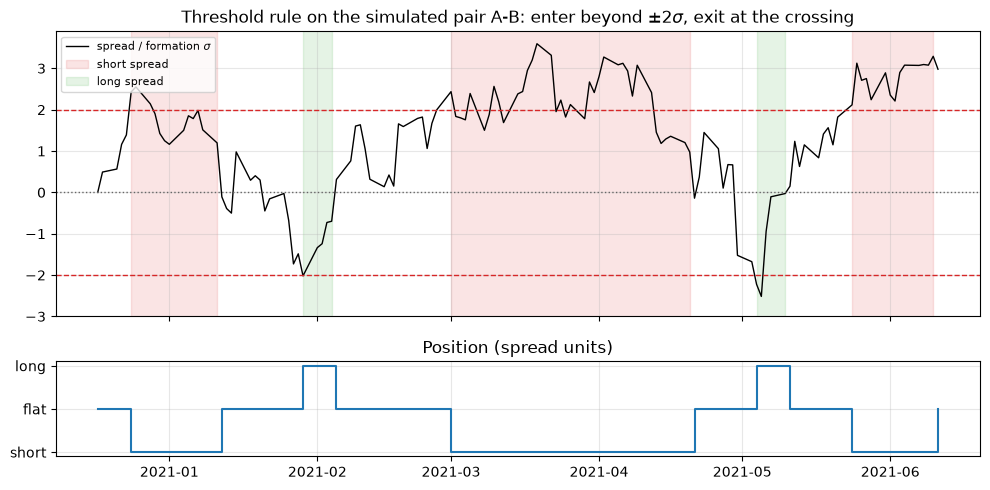

In [3]:
sigma = distance.spread(formation_sim, "A", "B").std()
window = sim.iloc[FORMATION - 1 : FORMATION + TRADING]
z = distance.spread(window, "A", "B") / sigma
position = threshold_positions(z, entry=ENTRY, exit=0.0)
position.iloc[-1] = 0.0

fig, (ax_z, ax_p) = plt.subplots(
    2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)
ax_z.plot(z, color="k", lw=1, label=r"spread / formation $\sigma$")
for level, style in ((ENTRY, "--"), (-ENTRY, "--"), (0, ":")):
    ax_z.axhline(level, color="C3" if level else "0.4", ls=style, lw=1)
ax_z.fill_between(z.index, -6, 6, where=position < 0, color="C3", alpha=0.12, label="short spread")
ax_z.fill_between(z.index, -6, 6, where=position > 0, color="C2", alpha=0.12, label="long spread")
ax_z.set_ylim(min(-3, z.min() - 0.3), max(3, z.max() + 0.3))
ax_z.set_title(
    r"Threshold rule on the simulated pair A-B: enter beyond $\pm 2\sigma$, exit at the crossing"
)
ax_z.legend(loc="upper left", fontsize=8)
ax_p.step(position.index, position, where="post", color="C0")
ax_p.set_yticks([-1, 0, 1], ["short", "flat", "long"])
ax_p.set_title("Position (spread units)")
fig.tight_layout()
save(fig, "threshold-rule.png")

The gap between the entry level (2σ) and the exit level (0) is **hysteresis**: once open, a
position stays open until the spread has come all the way back, instead of flickering on
and off around one level. This is a Schmitt trigger.

Run the full rolling backtest on the three simulated years (one-year formation, then
six-month trading periods):

In [4]:
sim_result = distance.ggr_backtest(sim, FORMATION, TRADING, n_pairs=2, entry=ENTRY)
print(sim_result.pairs[["period", "a", "b", "ssd", "trades"]].to_string(index=False))
print()
print(
    sim_result.trades[
        ["a", "b", "open", "close", "direction", "days", "return", "converged"]
    ].to_string(index=False)
)
performance(sim_result.committed).to_frame("simulated, committed capital").T

    period a b    ssd  trades
2020-12-18 A B 0.1711       5
2020-12-18 B D 0.3093       1
2021-06-14 A D 0.3895       0
2021-06-14 A B 0.7069       2
2021-12-07 B D 0.2125       2
2021-12-07 A D 0.2693       1
2022-06-01 A B 0.1591       2
2022-06-01 A D 0.1907       1

a b       open      close  direction  days  return  converged
A B 2020-12-24 2021-01-12         -1    13  0.0635       True
A B 2021-01-29 2021-02-05          1     5  0.0540       True
A B 2021-03-01 2021-04-21         -1    37  0.0554       True
A B 2021-05-04 2021-05-11          1     5  0.0503       True
A B 2021-05-24 2021-06-11         -1    14 -0.0210      False
B D 2021-05-19 2021-06-11          1    17 -0.0019      False
A B 2021-07-26 2021-08-13          1    14  0.0911       True
A B 2021-09-14 2021-11-11          1    42  0.0968       True
B D 2021-12-31 2022-02-03          1    24  0.0591       True
B D 2022-05-06 2022-05-31          1    17 -0.0014      False
A D 2022-04-12 2022-05-31          1    35 -0.0

,ann. return,ann. volatility,Sharpe
"simulated, committed capital",0.1232,0.0826,1.491


The genuine pair A–B makes money because its spread really does come back. Whenever the
impostor A–D (or B–D) is selected, its trades tend to end only when the trading period
runs out. The real data will be a mix of both kinds.

## 3. Real data: select pairs in one formation period

Universe: U1 (SPY, the sector ETFs and the classic pairs) plus the twelve financials of
U2, 2004–2025. XLRE and XLC only start in 2015 and 2018; a ticker with missing prices in a
formation window is simply not eligible in that window.

In [5]:
tickers = list(dict.fromkeys(universe.U1 + universe.LARGE_CAP_100_BY_SECTOR["Financials"]))
prices = data.clean_prices(data.load_prices(tickers, "2004-01-01", "2025-12-31"))
print(
    f"{len(tickers)} tickers, {len(prices)} days, {prices.index[0].date()} to {prices.index[-1].date()}"
)

formation_2018 = prices.loc["2018-01-01":"2018-12-31"]
top = distance.select_pairs(formation_2018, n=N_PAIRS)
top.head(10)

34 tickers, 5535 days, 2004-01-02 to 2025-12-31


,a,b,ssd
0,XLK,XLY,0.0742
1,XLF,XLI,0.0987
2,EWA,XLB,0.1131
3,EWC,XLB,0.1202
4,PEP,XLP,0.1411
5,BAC,XLF,0.1415
6,EWA,EWC,0.1609
7,KO,XLU,0.2546
8,XLRE,XLU,0.2668
9,JPM,SPY,0.2705


The closest pairs are mostly ETF against ETF (XLK–XLY, XLF–XLI, EWA–XLB) or an ETF
against one of its large holdings (BAC–XLF, PEP–XLP). That is what minimising distance
favours: assets whose prices hardly ever separate.

## 4. One trading period, step by step

Follow one classic pair, EWA (Australia) and EWC (Canada), through its 2018 formation year
and the first half of 2019.

days with a position: 110, pair return over the period: +3.71%


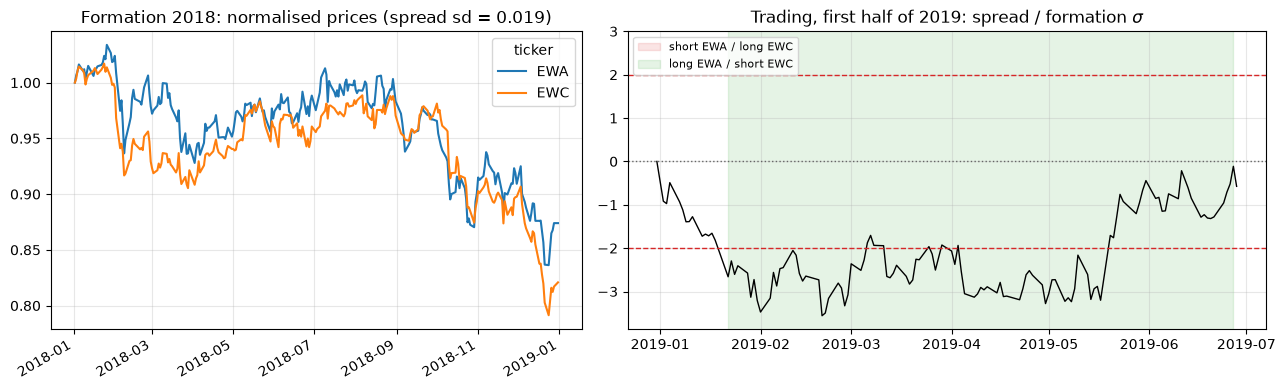

In [6]:
a, b = "EWA", "EWC"
form = prices.loc["2018-01-01":"2018-12-31"]
trade_window = prices.loc[form.index[-1] : "2019-06-30"]
sigma_ab = distance.spread(form, a, b).std()
z_ab = distance.spread(trade_window, a, b) / sigma_ab
pos_ab = threshold_positions(z_ab, entry=ENTRY)
pos_ab.iloc[-1] = 0.0

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 1.2]})
distance.normalise(form[[a, b]]).plot(ax=axes[0])
axes[0].set_title(f"Formation 2018: normalised prices (spread sd = {sigma_ab:.3f})")
axes[0].set_xlabel("")
axes[1].plot(z_ab, color="k", lw=1)
for level, style in ((ENTRY, "--"), (-ENTRY, "--"), (0, ":")):
    axes[1].axhline(level, color="C3" if level else "0.4", ls=style, lw=1)
axes[1].fill_between(
    z_ab.index, -6, 6, where=pos_ab < 0, color="C3", alpha=0.12, label="short EWA / long EWC"
)
axes[1].fill_between(
    z_ab.index, -6, 6, where=pos_ab > 0, color="C2", alpha=0.12, label="long EWA / short EWC"
)
axes[1].set_ylim(min(-3, z_ab.min() - 0.3), max(3, z_ab.max() + 0.3))
axes[1].set_title(r"Trading, first half of 2019: spread / formation $\sigma$")
axes[1].legend(loc="upper left", fontsize=8)
fig.tight_layout()
save(fig, "formation-trading-example.png")

pair_daily = distance.pair_returns(pos_ab, prices[a].pct_change(), prices[b].pct_change()).loc[
    trade_window.index[1:]
]
print(
    f"days with a position: {int(pos_ab.ne(0).sum())}, pair return over the period: {(1 + pair_daily).prod() - 1:+.2%}"
)

In late January the spread fell below −2σ (EWA cheap relative to EWC), so the rule went
long EWA and short EWC. The spread recovered most of the way, to about −0.5σ, but never
crossed zero, so the trade was closed when the period ended in June, with a gain of about
4% before costs. "Not converged" doesn't always mean "lost money".

## 5. Roll it through 2005–2025

Every six months: select the 20 closest pairs on the previous twelve months, trade them for
six months, close everything, repeat. The position decided at a close earns the next day's
return (`lag=1`).

In [7]:
result = distance.ggr_backtest(prices, FORMATION, TRADING, N_PAIRS, ENTRY, exit=0.0, lag=1)
trades = result.trades
summary = pd.DataFrame(
    {
        "committed capital": performance(result.committed),
        "employed capital": performance(result.employed),
    }
).T
print(
    f"{result.pairs['period'].nunique()} trading periods, {len(trades)} trades; "
    f"on average {result.open_pairs.mean():.1f} of {N_PAIRS} pairs open"
)
summary

42 trading periods, 872 trades; on average 9.5 of 20 pairs open


,ann. return,ann. volatility,Sharpe
committed capital,-0.0017,0.0443,-0.0393
employed capital,-0.0098,0.0896,-0.1098


Two ways to state the return, both from GGR:

- **committed capital:** the average over all 20 selected pairs, counting a pair with no
  open position as earning zero (the capital was set aside anyway);
- **employed capital:** the average over only the pairs that hold a position that day.

,ann. return,ann. volatility,Sharpe
2005-2009,-0.0143,0.0528,-0.2718
2010-2014,-0.0203,0.0423,-0.4808
2015-2019,0.0119,0.0306,0.3890
2020-2025,0.0129,0.0477,0.2708


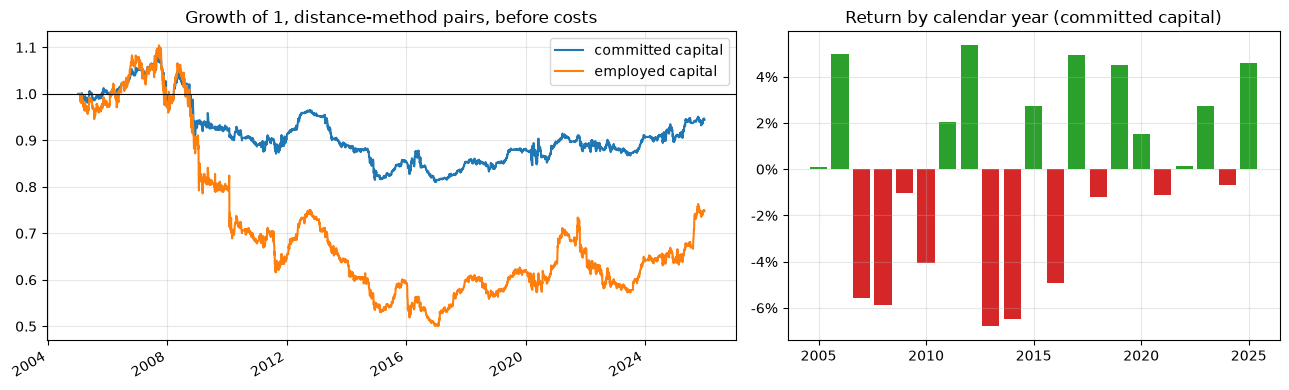

In [8]:
growth = pd.DataFrame(
    {
        "committed capital": (1 + result.committed).cumprod(),
        "employed capital": (1 + result.employed).cumprod(),
    }
)
yearly = result.committed.groupby(result.committed.index.year).apply(lambda r: (1 + r).prod() - 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.4, 1]})
growth.plot(ax=axes[0])
axes[0].axhline(1, color="k", lw=0.8)
axes[0].set_title("Growth of 1, distance-method pairs, before costs")
axes[0].set_xlabel("")
axes[1].bar(yearly.index, yearly.to_numpy(), color=np.where(yearly > 0, "C2", "C3"))
axes[1].set_title("Return by calendar year (committed capital)")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout()
save(fig, "ggr-cumulative.png")

subperiods = {
    "2005-2009": ("2005", "2009"),
    "2010-2014": ("2010", "2014"),
    "2015-2019": ("2015", "2019"),
    "2020-2025": ("2020", "2025"),
}
pd.DataFrame({k: performance(result.committed.loc[s:e]) for k, (s, e) in subperiods.items()}).T

## 6. How trades end: convergence vs divergence

A trade either **converges** (the spread crosses zero and the position closes with a
profit, before costs) or is still open when the six months run out and is closed by force.

                      count    mean  median
converged                                  
closed at period end    590 -0.0348 -0.0187
converged               282  0.0677  0.0649

share of trades that converge: 32%
median holding period: 55 days


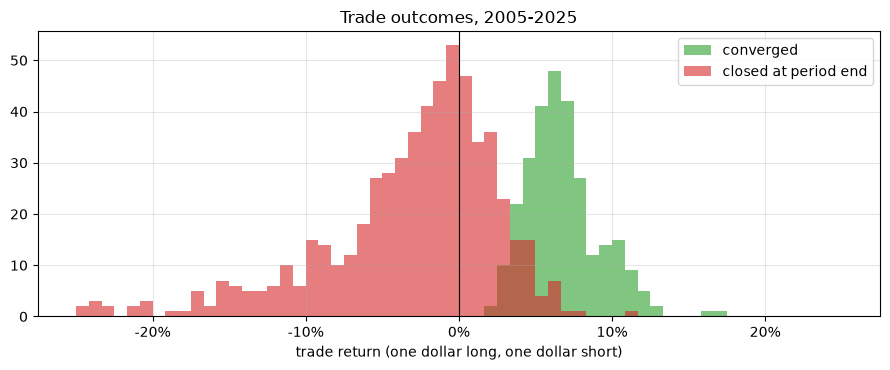

In [9]:
outcome = trades.groupby("converged")["return"].agg(["count", "mean", "median"])
outcome.index = outcome.index.map({True: "converged", False: "closed at period end"})
print(outcome)
print(f"\nshare of trades that converge: {trades['converged'].mean():.0%}")
print(f"median holding period: {trades['days'].median():.0f} days")

fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(-0.25, 0.25, 61)
ax.hist(
    trades.loc[trades["converged"], "return"], bins=bins, alpha=0.6, color="C2", label="converged"
)
ax.hist(
    trades.loc[~trades["converged"], "return"],
    bins=bins,
    alpha=0.6,
    color="C3",
    label="closed at period end",
)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("trade return (one dollar long, one dollar short)")
ax.set_title("Trade outcomes, 2005-2025")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend()
fig.tight_layout()
save(fig, "trade-outcomes.png")

The strategy is a race. Converged trades win by construction, but only about a third of
trades converge within six months; the rest are closed after the spread has kept
diverging, and they lose. The distance method selects pairs that *were* close, not pairs
that are pulled back together, so many selected spreads behave like the impostor A–D of
Section 1.

## 7. Trade at the signal close, or wait one day?

The signal uses a closing price. A closing trade happens at either the bid or the ask, so
a close that looks "far from the mean" is partly the bid–ask bounce, which reverses the
next day by itself. GGR therefore waited one day before trading (`lag=2` here).

In [10]:
waited = distance.ggr_backtest(prices, FORMATION, TRADING, N_PAIRS, ENTRY, exit=0.0, lag=2)
pd.DataFrame(
    {
        "trade at the signal close (lag 1)": performance(result.committed),
        "wait one day (lag 2)": performance(waited.committed),
    }
).T

,ann. return,ann. volatility,Sharpe
trade at the signal close (lag 1),-0.0017,0.0443,-0.0393
wait one day (lag 2),-0.0032,0.0440,-0.0733


Waiting a day costs a little here. For liquid ETFs and large banks the bid–ask spread is a
fraction of a basis point, so the bounce is tiny. In GGR's sample of all US stocks from 1962
on, where spreads were much wider, waiting a day lowered the returns noticeably, which is
why they report the conservative version.

## 8. Exercises

1. **Thresholds.** Vary the entry threshold (1, 1.5, 2, 3σ) and count the trades and the
   average return per trade. Note that this is your first data-snooping risk: every
   variant you try and keep is a hidden extra test (formalised in Module 6).
2. **Same sector only.** Restrict pairs to the same sector, against allowing any pair.
   Which works better here, and why might that be?
3. **What SSD rewards.** Explain in words why minimising SSD selects pairs with *low
   spread variance*, and why that may limit the profit per trade.

In [11]:
# Exercise 1

In [12]:
# Exercise 2

In [13]:
# Exercise 3